# Drift scenarios: input PSI (F22)

Four seeded samples of real rides: GBG500 training rides for normal and riskier mix, and the same SRV3490 development rides from city 1 with and without rotation conversion. The reference is derived from the GBG500 training population, so normal is not an independent false-alarm estimate. City 1 is unseen by model 1, not necessarily by model 2.

Generate reports first: `make scenario NAME=<name>` followed by `make drift DRIFT_CURRENT=reports/scenarios/<name>.parquet DRIFT_OUT=reports/drift/<name>` for each of `normal`, `riskier_mix`, `unseen_city`, `unit_bug`. Exit 3 means drift was detected and the report was written. These are offline input comparisons, not live dashboard validation.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from ride_classifier.config import ROOT, load_params
from ride_classifier.features.window_stats import FEATURES
from ride_classifier.viz.theme import apply_theme, save_fig

names = ['normal', 'riskier_mix', 'unseen_city', 'unit_bug']
paths = {name: ROOT / 'reports' / 'drift' / name / 'drift_report.json' for name in names}
missing = [str(path) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError('Generate the scenario reports first: ' + ', '.join(missing))
reports = {name: json.loads(path.read_text(encoding='utf-8')) for name, path in paths.items()}
for name, report in reports.items():
    print(f"{name}: {report['n_windows']} windows, {report['status']}")

normal: 1847 windows, ok
riskier_mix: 1951 windows, ok
unseen_city: 2832 windows, retrain_recommended
unit_bug: 2832 windows, retrain_recommended


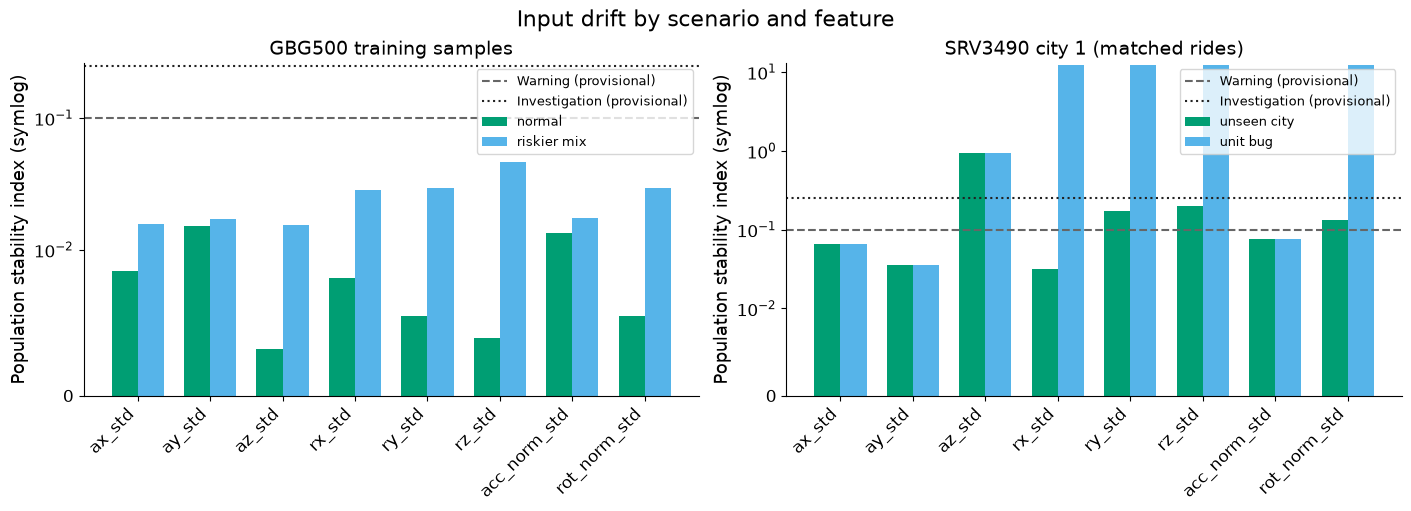

In [2]:
apply_theme()
values = np.array([[reports[name]['features'][feature]['psi'] for feature in FEATURES] for name in names])
thresholds = load_params()['drift']
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
x = np.arange(len(FEATURES))
for ax, indices, title in [(axes[0], [0, 1], 'GBG500 training samples'), (axes[1], [2, 3], 'SRV3490 city 1 (matched rides)')]:
    for offset, i in enumerate(indices):
        ax.bar(x + (offset - 0.5) * 0.36, values[i], width=0.36, label=names[i].replace('_', ' '))
    ax.axhline(thresholds['psi_alert'], color='#666666', linestyle='--', label='Warning (provisional)')
    ax.axhline(thresholds['psi_retrain'], color='#222222', linestyle=':', label='Investigation (provisional)')
    ax.set_title(title)
    ax.set_xticks(x, FEATURES, rotation=45, ha='right')
    ax.set_yscale('symlog', linthresh=0.01)
    ax.set_ylabel('Population stability index (symlog)')
    ax.legend(fontsize=9)
fig.suptitle('Input drift by scenario and feature')
save_fig(fig, 'F22', 'drift_scenario_psi')
plt.show()

The unit-bug comparison isolates the upstream conversion on the same rides; it calls for fixing the sender. The riskier sample may not cross the input threshold: that result must not be tuned away. Warning and investigation thresholds are provisional pending repeated normal-sample calibration. Outcome performance (F44) requires labelled API replay and is not yet measured.